In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm


np.random.seed(42)  # For reproducibility

In [2]:
main_df = pd.read_csv('../data/zombology/example_data.csv')  # Load your dataset here
main_df.head()

,snp_id,ref,alt,normal_1,normal_2,normal_3,normal_4,normal_5,normal_6,normal_7,...,zombie_91,zombie_92,zombie_93,zombie_94,zombie_95,zombie_96,zombie_97,zombie_98,zombie_99,zombie_100
0,chr1:944564,T,C,2,2,1,1,2,1,2,...,1,2,0,1,1,0,2,1,1,0
1,chr1:950243,A,C,0,1,1,1,0,1,0,...,0,0,1,0,1,0,0,0,1,0
2,chr1:959842,C,T,1,2,1,2,2,1,1,...,2,1,1,0,1,0,0,1,1,1
3,chr1:990417,T,C,0,2,2,2,1,2,2,...,0,2,2,0,2,2,2,1,1,2
4,chr1:1297065,C,T,2,1,0,1,0,1,2,...,2,1,2,2,2,0,2,1,1,1


In [3]:
snp_info = main_df.iloc[:, :3]  # Get the first three columns (SNP ID, Chromosome, Position)
df = main_df.iloc[:, 3:]  # Exclude the first column (ID)
samples = df.columns
df.head()

,normal_1,normal_2,normal_3,normal_4,normal_5,normal_6,normal_7,normal_8,normal_9,normal_10,...,zombie_91,zombie_92,zombie_93,zombie_94,zombie_95,zombie_96,zombie_97,zombie_98,zombie_99,zombie_100
0,2,2,1,1,2,1,2,0,1,1,...,1,2,0,1,1,0,2,1,1,0
1,0,1,1,1,0,1,0,0,0,0,...,0,0,1,0,1,0,0,0,1,0
2,1,2,1,2,2,1,1,1,1,1,...,2,1,1,0,1,0,0,1,1,1
3,0,2,2,2,1,2,2,2,2,2,...,0,2,2,0,2,2,2,1,1,2
4,2,1,0,1,0,1,2,2,1,1,...,2,1,2,2,2,0,2,1,1,1


In [4]:
snp_info.shape, df.shape, samples.shape

((48752, 3), (48752, 200), (200,))

In [5]:
labels = np.array([sample.split('_')[0] for sample in samples.tolist()])

In [6]:
df.iloc[0]

normal_1      2
normal_2      2
normal_3      1
normal_4      1
normal_5      2
             ..
zombie_96     0
zombie_97     2
zombie_98     1
zombie_99     1
zombie_100    0
Name: 0, Length: 200, dtype: int64

In [7]:
ref_allele_counts = df.apply(lambda row: (row == 0).sum() * 2 + (row == 1).sum(), axis=1)
alt_allele_counts = df.apply(lambda row: (row == 2).sum() * 2 + (row == 1).sum(), axis=1)

# minor allele frequency (MAF) calculation
maf = np.minimum(ref_allele_counts , alt_allele_counts) / 400

In [8]:
for ref, alt in zip(ref_allele_counts, alt_allele_counts):
    print(f"Reference: {ref}, Alternative: {alt}")
    break

Reference: 155, Alternative: 245


In [9]:
maf_threshold = 0.05
to_keep = maf >= maf_threshold

In [36]:
filtered_df = df[to_keep]
filtered_snp_info = snp_info[to_keep]
filtered_df.shape, filtered_snp_info.shape

((43908, 200), (43908, 3))

In [37]:
encoded_labels = np.where(labels == 'zombie', 1, 0)
encoded_labels

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1])

In [38]:
first_snp = filtered_df.iloc[0].values

def calculate_logistic_regression(snp_data, labels):
    X = sm.add_constant(snp_data)  # Add a constant term for the intercept
    model = sm.Logit(labels, X)  # Fit the logistic regression model
    result = model.fit(disp=False)  # Fit the model without displaying output
    return result

X = sm.add_constant(first_snp)
result = calculate_logistic_regression(first_snp, encoded_labels)

print(result.summary())

                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                  200
Model:                          Logit   Df Residuals:                      198
Method:                           MLE   Df Model:                            1
Date:                Fri, 20 Nov 2026   Pseudo R-squ.:               0.0008285
Time:                        23:04:32   Log-Likelihood:                -138.51
converged:                       True   LL-Null:                       -138.63
Covariance Type:            nonrobust   LLR p-value:                    0.6317
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.1126      0.274      0.410      0.682      -0.425       0.650
x1            -0.0919      0.192     -0.479      0.632      -0.468       0.284


In [39]:
p_value = result.pvalues[1] # p‑value for the SNP term

print(p_value)

0.6319294941622844


In [40]:
p_values = filtered_df.apply(lambda snp: calculate_logistic_regression(snp.values, encoded_labels).pvalues[1], axis=1)

/Users/threewestrick/Documents/workspace/intro_to_bioinformatics/.venv/lib/python3.10/site-packages/statsmodels/discrete/discrete_model.py:268: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [41]:
p_values_bonf = p_values * len(p_values)  

In [42]:
filtered_snp_info[p_values_bonf <= 0.05]

,snp_id,ref,alt
3723,chr1:221240797,G,A
4649,chr2:25491016,T,C
4714,chr2:27677691,G,A
7471,chr2:217890643,A,G
8289,chr2:239567125,T,C
9483,chr3:52739520,T,C
14491,chr5:42582527,C,T
15315,chr5:102282317,C,T
17087,chr5:179729519,A,G
17858,chr6:28169158,T,A


In [43]:
filtered_snp_info = filtered_snp_info.copy()
filtered_snp_info.loc[:, 'chr'] = filtered_snp_info.apply(lambda row: int(row['snp_id'].split(':')[0].replace('chr', '')), axis=1) 
filtered_snp_info.loc[:, 'position'] = filtered_snp_info.apply(lambda row: int(row['snp_id'].split(':')[1]), axis=1) 

In [44]:
filtered_snp_info

,snp_id,ref,alt,chr,position
0,chr1:944564,T,C,1,944564
1,chr1:950243,A,C,1,950243
2,chr1:959842,C,T,1,959842
3,chr1:990417,T,C,1,990417
4,chr1:1297065,C,T,1,1297065
...,...,...,...,...,...
48746,chr22:50278642,C,T,22,50278642
48747,chr22:50280136,T,C,22,50280136
48749,chr22:50294988,C,T,22,50294988
48750,chr22:50297435,T,C,22,50297435


In [45]:
neg_log_p_values = -np.log10(p_values_bonf)

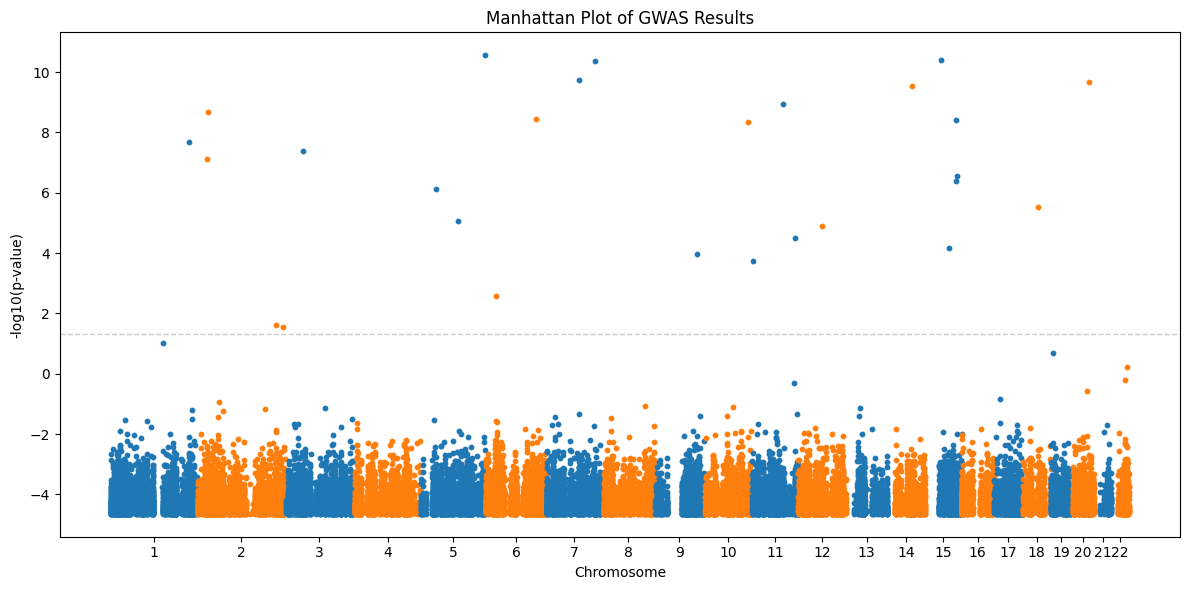

In [48]:
# Extract arrays directly from your filtered_snp_info DataFrame
filtered_snp_chromosomes = filtered_snp_info['chr'].to_numpy()
filtered_snp_positions = filtered_snp_info['position'].to_numpy()

# Create a DataFrame-like structure using NumPy and sort by chromosome and position
snp_data = np.column_stack((filtered_snp_chromosomes, filtered_snp_positions, neg_log_p_values))
snp_data = snp_data[np.lexsort((snp_data[:, 1], snp_data[:, 0]))]

# Pull the sorted columns back out so cumulative_positions aligns with snp_data
sorted_chroms = snp_data[:, 0]
sorted_positions = snp_data[:, 1]
sorted_neg_log_p = snp_data[:, 2]

# Compute cumulative positions
cumulative_positions = np.zeros_like(sorted_positions)
midpoints = []
unique_chroms = np.unique(sorted_chroms)

current_offset = 0
for chromosome in unique_chroms:
    chrom_mask = sorted_chroms == chromosome
    cumulative_positions[chrom_mask] = sorted_positions[chrom_mask] + current_offset
    midpoints.append((current_offset + np.max(cumulative_positions[chrom_mask])) / 2)
    current_offset = np.max(cumulative_positions[chrom_mask]) + 1  # Add a buffer between chromosomes

# Prepare the Manhattan plot
plt.figure(figsize=(12, 6))
colors = ['#1f77b4', '#ff7f0e']
dot_size = 10

for i, chromosome in enumerate(unique_chroms):
    chrom_mask = sorted_chroms == chromosome
    plt.scatter(
        cumulative_positions[chrom_mask],
        sorted_neg_log_p[chrom_mask],
        c=colors[i % 2],
        s=dot_size,
        label=f'Chromosome {int(chromosome)}'
    )

# Add chromosome labels at midpoints (cast to int so ticks don't show as 1.0, 2.0)
plt.xticks(midpoints, unique_chroms.astype(int))

# Add significance line 
# (Note: use 0.05 if p_values_bonf is already Bonferroni-adjusted, or 0.05 / len(snp_data) if raw)
sig_thresh = -np.log10(0.05) 
plt.axhline(
    y=sig_thresh,
    color='grey',
    linestyle='--',
    linewidth=1,
    alpha=0.4
)

# Add labels and title
plt.xlabel('Chromosome')
plt.ylabel('-log10(p-value)')
plt.title('Manhattan Plot of GWAS Results')

# Save and show the plot
plt.tight_layout()
# plt.savefig("output/manhattan_plot.pdf")
plt.show()